In [1]:
from __future__ import annotations

import string 
from dataclasses import dataclass, field
from pathlib import Path
from typing import Iterable, Optional, Dict, List, Optional, Sequence, Tuple
import cftime
import datetime as _dt
import matplotlib.dates as mdates

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from __future__ import annotations


In [29]:
# -------------------------
# Plot config
# -------------------------
@dataclass
class SswMonthlyPlotConfig:
    diag_dir: Path
    ref: str
    exp_keys: list[str]
    style_map: dict[str, dict]

    plevs_hpa: tuple[float, float] = (10.0, 100.0)
    vars_core: tuple[str, str, str] = ("u_55_65N", "z_pcap", "t_pcap")
    unit_core: tuple[str, str, str] = (r"m s$^{-1}$", r"gpm", r"K")
    vars_label: tuple[str, str, str] = ("U", "Z", "T")
    vars_region: tuple[str, str, str] = ("(55-65N)", "(60-90N)", "(60-90N)")
    ssw_window: tuple[str, str] = ("2012-11", "2013-03")
    running_rmse_months: int = 3
    early_windows: tuple[tuple[int, int], ...] = ((0, 3), (0, 6))
    dpi: int = 600

    # y-limits by variable name, then by pressure level (hPa)
    ylim_map: dict[str, dict[float, tuple[float, float]]] = field(default_factory=lambda: {
        "u_55_65N": {
            10.0: (-45, 45),
            100.0: (-10, 10),
        },
        "u_55_65N_rmse": {
            10.0: (0, 30),
            100.0: (0, 10),
        },
        "z_pcap": {
            10.0: (-150, 80),
            100.0: (-25, 40),
        },
        "t_pcap": {
            10.0: (-30, 12),
            100.0: (-12, 6),
        },
    })
    
    raw_map: dict[str, dict[float, tuple[float, float]]] = field(default_factory=lambda: {
        "u_55_65N": {
            10.0: (-45, 45),
            100.0: (-20, 10),
        },
        "u_55_65N_rmse": {
            10.0: (0, 30),
            100.0: (0, 10),
        },
        "z_pcap": {
            10.0: (-150, 80),
            100.0: (-25, 40),
        },
        "t_pcap": {
            10.0: (-30, 12),
            100.0: (-12, 6),
        },
    })
    
class SswMonthlyPlotter:
    """
    Plotter for ssw_monthly_<EXP>_vs_<REF>.nc files created by SswMonthlyAnalyzer.

    Assumes each file contains:
      - time(time), plev(plev)
      - {var}(time, plev)
      - {var}_bias_<REF>(time, plev)
      - {var}_rmse_<window>_<REF>(plev)  for windows: all, winter, ssw, lead10_14, etc.
    """

    def __init__(self, cfg: SswMonthlyPlotConfig):
        self.cfg = cfg

    # -------------------------
    # IO helpers
    # -------------------------
    def _nc_path(self, exp: str) -> Path:
        return self.cfg.diag_dir / f"ssw_monthly_{exp}_vs_{self.cfg.ref}.nc"

    def open(self, exp: str) -> xr.Dataset:
        p = self._nc_path(exp)
        if not p.exists():
            raise FileNotFoundError(f"Missing diagnostics file: {p}")
        return xr.open_dataset(p)

    # -------------------------
    # coordinate helpers
    # -------------------------
    def _plev_pa_from_hpa(self, hpa: float) -> float:
        return float(hpa) * 100.0

    def _sel_plev(self, da: xr.DataArray, plev_hpa: float) -> xr.DataArray:
        plev_pa = self._plev_pa_from_hpa(plev_hpa)
        # exact match if possible, else nearest
        return da.sel(plev=plev_pa, method="nearest")

    def _time_to_datetime64(self, t: xr.DataArray) -> np.ndarray:
        """
        Matplotlib does not like cftime objects in many environments.
        Convert to numpy datetime64 (approximate but fine for monthly labels).
        """
        vals = t.values
        out = []
        for tt in vals:
            if isinstance(tt, cftime.datetime):
                out.append(np.datetime64(f"{tt.year:04d}-{tt.month:02d}-{tt.day:02d}"))
            else:
                # already datetime64 or similar
                out.append(np.datetime64(tt))
        return np.array(out)

    def _next_month(y: int, m: int) -> tuple[int, int]:
        if m == 12:
            return (y + 1, 1)
        return (y, m + 1)
    
    def _shade_ssw(
        self, ax, 
        time_dt64: np.ndarray | None = None,
        x: float = 0.43,
        y: float = 0.02 
    ):
        """
        Shade the SSW window using cfg.ssw_window = ("YYYY-MM","YYYY-MM").
        """
        y0, m0 = self.cfg.ssw_window[0].split("-")
        y1, m1 = self.cfg.ssw_window[1].split("-")
    
        ssw_start = np.datetime64(f"{int(y0):04d}-{int(m0):02d}-01")
    
        # end is exclusive: first day of month after (y1,m1)
        end_y, end_m = int(y1), int(m1) + 1
        if end_m == 13:
            end_m = 1
            end_y += 1
        ssw_end_excl = np.datetime64(f"{end_y:04d}-{end_m:02d}-01")
    
        ax.axvspan(
            ssw_start,
            ssw_end_excl,
            color="0.85",      # light grey (recommended)
            alpha=0.6,
            zorder=0,          # keep behind lines
            linewidth=0,
        )
    
        ax.text(
            x,
            y,
            "SSW window",
            transform=ax.transAxes,
            va="bottom",
            fontsize=10,
            color="0.35",
        )

    def open_by_ref(self, exp: str, ref: str) -> xr.Dataset:
        p = self.cfg.diag_dir / f"ssw_monthly_{exp}_vs_{ref}.nc"
        if not p.exists():
            raise FileNotFoundError(f"Missing diagnostics file: {p}")
        return xr.open_dataset(p)

    def _series_center_band(
        self,
        exp: str,
        varname_fmt: str,      # e.g. "{v}_bias_{ref}"
        v: str,
        p_hpa: float,
        refs: tuple[str, str] = ("ERA5", "ERAI"),
        center: str = "mean",  # "mean" or "ERA5" or "ERAI"
    ):
        p_pa = float(p_hpa) * 100.0
    
        dsA = self.open_by_ref(exp, refs[0])
        dsB = self.open_by_ref(exp, refs[1])
        try:
            nameA = varname_fmt.format(v=v, ref=refs[0])
            nameB = varname_fmt.format(v=v, ref=refs[1])
    
            if nameA not in dsA or nameB not in dsB:
                raise KeyError(f"{exp}: missing {nameA} or {nameB}")
    
            a = self._sel_plev(dsA[nameA], p_hpa)  # (time,)
            b = self._sel_plev(dsB[nameB], p_hpa)
    
            # align time just in case
            a, b = xr.align(a, b, join="inner")
    
            t = self._time_to_datetime64(a["time"])
    
            lo = xr.ufuncs.minimum(a, b).values
            hi = xr.ufuncs.maximum(a, b).values
    
            if center == refs[0]:
                c = a.values
            elif center == refs[1]:
                c = b.values
            else:
                c = 0.5 * (a.values + b.values)
    
            return t, c, lo, hi
        finally:
            dsA.close()
            dsB.close()
            
    def _nc_path_ref(self, exp: str, ref: str) -> Path:
        return self.cfg.diag_dir / f"ssw_monthly_{exp}_vs_{ref}.nc"
    
    def open_ref(self, exp: str, ref: str) -> xr.Dataset:
        p = self._nc_path_ref(exp, ref)
        if not p.exists():
            raise FileNotFoundError(f"Missing diagnostics file: {p}")
        return xr.open_dataset(p)
        
    def _time_to_mpl(self, t: xr.DataArray) -> np.ndarray:
        """
        Convert cftime or numpy.datetime64 time to matplotlib date floats.
        Required for fill_between().
        """
        vals = t.values
        dt_list = []
        for tt in vals:
            if isinstance(tt, cftime.datetime):
                dt_list.append(_dt.datetime(tt.year, tt.month, tt.day))
            else:
                s = np.datetime_as_string(tt, unit="D")
                dt_list.append(_dt.datetime.fromisoformat(s))
        return mdates.date2num(dt_list)
    
    # -------------------------
    # Figure 1: Bias time series (mechanistic)
    # -------------------------
    def plot_bias_timeseries_two_refs(
        self,
        refs: tuple[str, str] = ("ERA5", "ERAI"),
        center: str = "mean",  # "mean" | "ERA5" | "ERAI"
        out_png: Optional[Path] = None,
        show: bool = True,
        fontz: int = 12,
        band_alpha: float = 0.18,   # <--- add: makes band visible but not overpowering
        fig_idx: int = 0,
    ):
        cfg = self.cfg
        refA, refB = refs
    
        nrows = len(cfg.vars_core)
        ncols = len(cfg.plevs_hpa)
        fig, axes = plt.subplots(nrows, ncols, figsize=(12.0, 8.5), sharex=True)
        if nrows == 1:
            axes = np.array([axes])
        if ncols == 1:
            axes = axes[:, None]
        for i, (v, vlab, vreg) in enumerate( zip(cfg.vars_core, cfg.vars_label, cfg.vars_region)):
            for j, p_hpa in enumerate(cfg.plevs_hpa):
                ax = axes[i, j]
                mm = j + i*len(cfg.plevs_hpa)
                # set y-lim once per panel (not inside exp loop)
                ylim = cfg.ylim_map.get(v, {}).get(p_hpa)
                if ylim is not None:
                    ax.set_ylim(*ylim)
    
                for exp in cfg.exp_keys:
                    dsA = self.open_ref(exp, refA)
                    dsB = self.open_ref(exp, refB)
    
                    t = self._time_to_mpl(dsA["time"])  # matplotlib datetime list
    
                    nameA = f"{v}_bias_{refA}"
                    nameB = f"{v}_bias_{refB}"
                    if nameA not in dsA:
                        raise KeyError(f"{self._nc_path_ref(exp, refA)} missing {nameA}")
                    if nameB not in dsB:
                        raise KeyError(f"{self._nc_path_ref(exp, refB)} missing {nameB}")
    
                    yA = self._sel_plev(dsA[nameA], p_hpa).values.astype(float)
                    yB = self._sel_plev(dsB[nameB], p_hpa).values.astype(float)

                    if v == "z_pcap" and cfg.unit_core[i] == "gpm":
                        yA = yA / 10.0
                        yB = yB / 10.0
                        
                    dsA.close()
                    dsB.close()
    
                    # center/band
                    if center.lower() == "mean":
                        yC = 0.5 * (yA + yB)
                        d  = 0.5 * np.abs(yA - yB)   # half-spread between refs
                        ylo = yC - d
                        yhi = yC + d
                        center_label = f"mean({refA},{refB})"
                        band_label   = "±½|Δref|"
                    elif center.upper() == refA:
                        yC = yA
                        ylo = np.minimum(yA, yB)
                        yhi = np.maximum(yA, yB)
                        center_label = refA
                        band_label   = f"{refA}–{refB}"
                    elif center.upper() == refB:
                        yC = yB
                        ylo = np.minimum(yA, yB)
                        yhi = np.maximum(yA, yB)
                        center_label = refB
                        band_label   = f"{refA}–{refB}"
                    else:
                        raise ValueError(f"center must be 'mean', '{refA}', or '{refB}'")
    
                    style = cfg.style_map.get(exp, {})
                    (line,) = ax.plot(t, yC, label=exp, **style)
    
                    band_color = style.get("color", line.get_color())
                    ax.fill_between(
                        t, ylo, yhi,
                        color=band_color,
                        alpha=band_alpha,
                        linewidth=0.0,
                        zorder=line.get_zorder() - 1,
                    )
                    
                ax.set_ylabel(fr"Bias ({cfg.unit_core[i]})", fontsize=fontz*0.95)

                # SSW shading (make sure your _shade_ssw uses light grey)
                self._shade_ssw(ax)
    
                ax.grid(True, alpha=0.3)
                ax.axhline(0, color = "black", linewidth=0.1, alpha=0.8)
    
                # x tick formatting
                ax.tick_params(axis="x", labelrotation=30, labelsize=fontz*0.95)
                ax.tick_params(axis="y", labelsize=fontz*0.95)
                
                for lab in ax.get_xticklabels():
                    lab.set_horizontalalignment("right")
    
                # titles (left + right)
                panel_label = f"({string.ascii_lowercase[fig_idx + mm]})"
                ax.set_title(f"{panel_label} {vlab}({int(p_hpa)}-hPa) bias", loc="left", fontsize=fontz)
                ax.set_title(f"Region: {vreg}", loc="right", fontsize=fontz)
                ax.text(0.12, 0.90, f"Ref: {center_label}", transform=ax.transAxes, fontsize=fontz * 0.8)

        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.legend(
            handles, labels,
            loc="lower center",
            ncol=len(cfg.exp_keys),
            fontsize=fontz * 0.90,
            frameon=True,
        )
    
        fig.tight_layout(rect=[0.02, 0.06, 0.98, 0.98])
    
        if out_png is not None:
            out_png = Path(out_png)
            out_pdf = out_png.with_suffix(".pdf")
    
            fig.savefig(out_png, dpi=cfg.dpi, bbox_inches="tight")
            fig.savefig(out_pdf, bbox_inches="tight")
    
            print("Wrote:", out_png)
            print("Wrote:", out_pdf)
    
        if show:
            plt.show()
        plt.close(fig)


    # -------------------------
    # Figure 2: Bias + running RMSE (mechanistic)
    # -------------------------
    def plot_bias_and_running_rmse_two_refs(
        self,
        out_png: Optional[Path] = None,
        show: bool = True,
        var: str = "u_55_65N",
        plevs_hpa: tuple[float, float] = (10.0, 100.0),
        refs: tuple[str, str] = ("ERA5", "ERAI"),
        center: str = "mean",
        band_alpha: float = 0.18,
        figsize: int = (10,10),
        fontz: int = 16,
        fig_idx: int = 0,
        wspace: float = 0.15,
        hspace: flot = 0.22,
        ncols: int = None,
        nrows: int = None,
        sharex: bool = True,
        legend_on: bool = True, 
    ):
        cfg = self.cfg
        win = cfg.running_rmse_months
        refA, refB = refs
        
        i = cfg.vars_core.index(var)
        vlab  = cfg.vars_label[i]
        vreg  = cfg.vars_region[i]

        if ncols is None and nrows is None:
            fig, axes = plt.subplots(2, len(plevs_hpa), figsize=(12.0, 6.0), sharex=sharex)
        else:
            fig, axes = plt.subplots(nrows, ncols, figsize=figsize, sharex=sharex)
            
        if len(plevs_hpa) == 1:
            axes = np.array([[axes[0]], [axes[1]]])
    
        for j, p_hpa in enumerate(plevs_hpa):
            ax_bias = axes[0, j]
            ax_rmse = axes[1, j]
    
            for exp in cfg.exp_keys:
                # --- bias band ---
                t, c, lo, hi = self._series_center_band(
                    exp=exp,
                    varname_fmt="{v}_bias_{ref}",
                    v=var,
                    p_hpa=p_hpa,
                    refs=refs,
                    center=center,
                )
                st = cfg.style_map.get(exp, {})
                ax_bias.plot(t, c, label=exp, **st)
                ax_bias.fill_between(t, lo, hi, alpha=band_alpha)
                 # x tick formatting
                ax_bias.tick_params(axis="x", labelrotation=30, labelsize=fontz*0.95)
                ax_bias.tick_params(axis="y", labelsize=fontz*0.95)
                
                # --- running RMSE band (computed from bias for each ref) ---
                if win is not None and win >= 2:
                    # load bias for each ref, compute running RMSE, then band
                    dsA = self.open_by_ref(exp, refs[0])
                    dsB = self.open_by_ref(exp, refs[1])
                    try:
                        a = self._sel_plev(dsA[f"{var}_bias_{refs[0]}"], p_hpa)
                        b = self._sel_plev(dsB[f"{var}_bias_{refs[1]}"], p_hpa)
                        a, b = xr.align(a, b, join="inner")
    
                        rA = np.sqrt((a**2).rolling(time=win, center=True).mean(skipna=True)).values
                        rB = np.sqrt((b**2).rolling(time=win, center=True).mean(skipna=True)).values
    
                        rlo = np.minimum(rA, rB)
                        rhi = np.maximum(rA, rB)
                        if center == refs[0]:
                            rc = rA
                        elif center == refs[1]:
                            rc = rB
                        else:
                            rc = 0.5 * (rA + rB)
    
                        ax_rmse.plot(t, rc, label=exp, **st)
                        ax_rmse.fill_between(t, rlo, rhi, alpha=band_alpha)
                    finally:
                        dsA.close()
                        dsB.close()
                        
                # x tick formatting
                ax_rmse.tick_params(axis="x", labelrotation=30, labelsize=fontz*0.95)
                ax_rmse.tick_params(axis="y", labelsize=fontz*0.95)
                
                for lab in ax_rmse.get_xticklabels():
                    lab.set_horizontalalignment("right")
    
            self._shade_ssw(ax_bias, t)
            self._shade_ssw(ax_rmse, t)
            
            ax_bias.axhline(0, color='black', linewidth=0.5, alpha=0.5)
            
            ax_bias.grid(True, alpha=0.3)
            ax_rmse.grid(True, alpha=0.3)
            
            panel_label1=f"({string.ascii_lowercase[fig_idx+j]})"
            ax_bias.set_title(f"{panel_label1} {vlab}({int(p_hpa)}-hPa) bias", loc="left", fontsize=fontz*1.0)
            ax_bias.set_title(f"Region: {vreg}", loc="right", fontsize=fontz*1.0)
            ax_bias.set_ylabel(fr"Bias (m s$^{-1}$)", fontsize=fontz*0.95)
            ax_bias.text(0.12, 0.90, f"Ref: mean({refA},{refB})", transform=ax_bias.transAxes, fontsize=fontz * 0.8)

            panel_label2=f"({string.ascii_lowercase[fig_idx+j+1]})"
            ax_rmse.set_title(f"{panel_label2} {vlab}({int(p_hpa)}hPa) {win}-month running RMSE ", loc="left", fontsize=fontz*1.0)
            ax_rmse.set_title(f"Region: {vreg}", loc="right", fontsize=fontz*1.0)
            ax_rmse.set_ylabel(fr"RMSE (m s$^{-1}$)",fontsize=fontz*0.95)
            ax_rmse.text(0.12, 0.90, f"Ref: mean({refA},{refB})", transform=ax_rmse.transAxes, fontsize=fontz * 0.8)

    
        if legend_on: 
            handles, labels = axes[0, 0].get_legend_handles_labels()
            fig.legend(
                handles, labels,
                loc="lower center",
                ncol=len(cfg.exp_keys),
                fontsize=fontz * 0.90,
                frameon=True,
            )
    
        fig.tight_layout(rect=[0.02, 0.06, 0.98, 0.98])
        fig.subplots_adjust(hspace=hspace, wspace=wspace)   # increase horizontal space between panels

        if out_png is not None:
            out_png = Path(out_png)
            out_pdf = out_png.with_suffix(".pdf")
    
            fig.savefig(out_png, dpi=cfg.dpi, bbox_inches="tight")
            fig.savefig(out_pdf, bbox_inches="tight")
    
            print("Wrote:", out_png)
            print("Wrote:", out_pdf)
    
        if show:
            plt.show()
        plt.close(fig)

    def _rmse_name(self, var: str, ref: str, window_type: str, window):
        if window_type == "ssw":
            return f"{var}_rmse_ssw_{ref}"
        elif window_type == "lead":
            if window is None:
                raise ValueError("window must be provided for window_type='lead'")
            L0, L1 = window
            return f"{var}_rmse_lead{L0:02d}_{L1:02d}_{ref}"
        else:
            raise ValueError(f"Unknown window_type='{window_type}'")

    @staticmethod
    def _sel_plev_pa(da: xr.DataArray, plev_pa: float) -> xr.DataArray:
        if "plev" in da.dims:
            return da.sel(plev=plev_pa, method="nearest")
        return da

    def _rmse_from_bias_lead_window(
        self,
        ds: xr.Dataset,
        var: str,
        ref: str,
        plev_pa: float,
        window: tuple[int, int],
    ) -> float:
        """
        Compute RMSE over lead-month indices [L0..L1] from bias time series.
        """
        L0, L1 = window
        bias_name = f"{var}_bias_{ref}"
        if bias_name not in ds:
            raise KeyError(f"Missing '{bias_name}' needed for fallback RMSE computation.")

        bias = ds[bias_name]
        bias = self._sel_plev_pa(bias, plev_pa)

        # Lead month indexing: time index 0 corresponds to Jan 2012
        # Use inclusive L1
        bias_win = bias.isel(time=slice(L0, L1 + 1))
        if bias_win.sizes.get("time", 0) == 0:
            return float("nan")

        rmse = np.sqrt((bias_win ** 2).mean("time"))
        return float(rmse.values)

    @staticmethod
    def _get_rmse_at_plev_from_var(ds: xr.Dataset, rmse_name: str, plev_pa: float) -> float:
        """
        Read precomputed RMSE field from ds at plev.
        """
        da = ds[rmse_name]
        if "plev" in da.dims:
            return float(da.sel(plev=plev_pa, method="nearest").values)
        return float(da.values)

    def _get_rmse_for_ref_exp(
        self,
        exp: str,
        ref: str,
        var: str,
        plev_pa: float,
        window_type: str,
        window,
    ) -> float:
        """
        Robust RMSE getter:
          - for 'ssw': require precomputed *_rmse_ssw_<ref>
          - for 'lead': try precomputed *_rmse_leadXX_YY_<ref>, else compute from bias
        """
        fn = Path(self.cfg.diag_dir) / f"ssw_monthly_{exp}_vs_{ref}.nc"
        if not fn.exists():
            raise FileNotFoundError(f"Missing diagnostics file: {fn}")

        rmse_name = self._rmse_name(var, ref, window_type, window)

        with xr.open_dataset(fn) as ds:
            if rmse_name in ds:
                return self._get_rmse_at_plev_from_var(ds, rmse_name, plev_pa)

            # fallback only for lead windows
            if window_type == "lead":
                return self._rmse_from_bias_lead_window(ds, var, ref, plev_pa, window)

            raise KeyError(
                f"Missing '{rmse_name}' in {fn}. "
                f"Available vars (head): {list(ds.data_vars)[:40]}"
            )
            
    def plot_rmse_attribution_bars_two_refs(
        self,
        var: str = "u_55_65N",
        plev_hpa: float = 10.0,
        window_types: list[str] = ["ssw"],                 # e.g., ["ssw", "lead"]
        windows: list[tuple[int, int] | None] = [None],    # [None, (0,3), ...]
        ylims: list[tuple[int, int] | None] = [None],    # [None, (0,3), ...]
        refs: tuple[str, str] = ("ERA5", "ERAI"),
        include_dartop_minus_era5op: bool = True,
        as_percent: bool = True,
        percent_mode: str = "ctrl",   # "step" or "ctrl"
        out_dir: Path | None = None,
        show: bool = True,
        figsize: tuple = (12.8, 4.8),
        fontz: int = 12,
        fig_idx: int = 0,
        wspace: float=0.15,
        hspace: float=0.15
    ):
        cfg = self.cfg
        exp_keys = cfg.exp_keys
        plev_pa = float(plev_hpa) * 100.0
        refA,refB = refs 
        
        if len(window_types) != len(windows):
            raise ValueError(f"window_types and windows must have same length. got {len(window_types)} vs {len(windows)}")
    
        # --- helpers ---
        def load_rmse_dict(ref: str, window_type: str, window: tuple[int, int] | None) -> dict[str, float]:
            return {
                exp: self._get_rmse_for_ref_exp(exp, ref, var, plev_pa, window_type, window)
                for exp in exp_keys
            }
    
        def build_bars(rmse: dict[str, float]) -> list[tuple[str, float]]:
            bars = [
                # Group A: total change vs CTRL
                ("ERA5(atm)",              rmse["ERA5BL"] - rmse["CTRL"]),
                ("ERA5(atm+lnd)",          rmse["ERA5OP"] - rmse["CTRL"]),
                ("DART(atm)",              rmse["DARTBL"] - rmse["CTRL"]),
                ("DART(lnd)",              rmse["DARTBA"] - rmse["CTRL"]),
                ("DART(atm+lnd)",          rmse["DARTOP"] - rmse["CTRL"]),
                ("DART(atm)+ERA5(lnd)",    rmse["DARTAE"] - rmse["CTRL"]),
                # Group B: incremental land effect (step)
                ("+LND | ERA5 (atm)",      rmse["ERA5OP"] - rmse["ERA5BL"]),
                ("+LND | DART (atm)",      rmse["DARTOP"] - rmse["DARTBL"]),
            ]
            if include_dartop_minus_era5op:
                bars.append(("DART − ERA5", rmse["DARTOP"] - rmse["ERA5OP"]))
            return bars
    
        def build_denoms(rmse: dict[str, float]) -> np.ndarray:
            # default denom list aligned with build_bars() ordering
            den = [
                rmse["CTRL"],  # ERA5 atm − CTRL
                rmse["CTRL"],  # ERA5 atm+lnd − CTRL
                rmse["CTRL"],  # DART atm − CTRL
                rmse["CTRL"],  # DART lnd − CTRL
                rmse["CTRL"],  # DART atm+lnd − CTRL
                rmse["CTRL"],  # DART(atm)+ERA5(lnd) − CTRL
                rmse["CTRL"],  # +LND | ERA5(atm) step
                rmse["CTRL"],  # +LND | DART(atm) step
            ]
            if include_dartop_minus_era5op:
                den.append(rmse["CTRL"])
            return np.array(den, dtype=float)
    
        # --- figure layout: one axis per window ---
        nwin = len(window_types)
        fig, axes = plt.subplots(nwin, 1, figsize=figsize, sharey=False)    
        results = {}
    
        for k, (window_type, window, ylim) in enumerate(zip(window_types, windows, ylims)):
            ax = axes[k]
    
            # labels for panel title
            if window_type == "ssw":
                win_lab = "SSW window (Nov 2012–Mar 2013)"
                win_str = "ssw_window"
            elif window_type == "lead":
                if window is None:
                    raise ValueError("window must be provided for window_type='lead'")
                L0, L1 = window
                win_lab = f"Lead window ({L0}–{L1} months)"
                win_str = f"l{L0}–{L1}mo"
            else:
                raise ValueError(f"Unknown window_type='{window_type}'")
    
            # recompute RMSE dicts for THIS window
            rmseA = load_rmse_dict(refs[0], window_type, window)
            rmseB = load_rmse_dict(refs[1], window_type, window)
    
            barsA = build_bars(rmseA)
            barsB = build_bars(rmseB)
    
            labels = [b[0] for b in barsA]
            valsA = np.array([b[1] for b in barsA], dtype=float)
            valsB = np.array([b[1] for b in barsB], dtype=float)
    
            #vmin = np.minimum(valsA, valsB)
            #vmax = np.maximum(valsA, valsB)
            #vbar = 0.5 * (valsA + valsB)
            #yerr = np.vstack([vbar - vmin, vmax - vbar])
            vbar = 0.5 * (valsA + valsB)                 # mean over [ERA5, ERAI]
            vrng = 0.5 * np.abs(valsA - valsB)           # half-range across refs
            yerr = vrng                                  # symmetric whiskers: mean +/- half-range
            
            if as_percent:
                denA = build_denoms(rmseA)
                denB = build_denoms(rmseB)
    
                if percent_mode == "ctrl":
                    denA[:] = rmseA["CTRL"]
                    denB[:] = rmseB["CTRL"]
                elif percent_mode == "step":
                    # If you ever want true step-normalization later, implement here.
                    # For now keep ctrl-normalization behavior unless explicitly requested.
                    pass
                else:
                    raise ValueError("percent_mode must be 'ctrl' or 'step'")
    
                den_bar = 0.5 * (denA + denB)
                den_bar = np.where(np.isfinite(den_bar) & (den_bar != 0.0), den_bar, np.nan)
    
                vbar = 100.0 * (vbar / den_bar)
                yerr = 100.0 * (yerr / den_bar)
    
                ax.set_ylabel(r"$\Delta$RMSE / RMSE(CTRL) (%)", fontsize=fontz * 0.95)
            else:
                ax.set_ylabel(r"$\Delta$RMSE (new − old)$", fontsize=fontz * 0.95)
    
            x = np.arange(len(labels))
            ax.axhline(0.0, color="black", linewidth=0.5, alpha=0.8)
    
            ax.bar(
                x, vbar,
                color="0.7",
                edgecolor="0.3",
                linewidth=0.8,
                zorder=2,
            )
            ax.errorbar(
                x, vbar, yerr=yerr,
                fmt="none",
                ecolor="k",
                elinewidth=1.2,
                capsize=4,
                capthick=1.2,
                zorder=3,
            )
            
            if ylim is not None:
                ax.set_ylim(*ylim)
                
            panel_label = f"({string.ascii_lowercase[fig_idx + k]})"
            ax.set_title(f"{panel_label} RMSE attribution", loc="left", fontsize=fontz)
            ax.set_title(win_lab, loc="right", fontsize=fontz)
            if k == len(window_types)-1:
                ax.set_xticks(x)
                ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=fontz * 0.95)
            else:
                ax.set_xticks(x)
                ax.set_xticklabels([])
            
            ax.tick_params(axis="x", labelsize=fontz * 0.95)
            ax.tick_params(axis="y", labelsize=fontz * 0.95)
            
            # group separators
            ax.axvline(5.5, color="red", linestyle=":", linewidth=1.0, alpha=0.8)
            ax.axvline(7.5, color="red", linestyle=":", linewidth=1.0, alpha=0.8)
    
            # group labels
            ax.text(0.35, 0.97, "Total vs CTRL", transform=ax.transAxes, ha="center", va="top", fontsize=fontz * 0.95)
            ax.text(0.73, 0.97, "Land effect",   transform=ax.transAxes, ha="center", va="top", fontsize=fontz * 0.95)
            ax.text(0.93, 0.97, "DA − ERA5",     transform=ax.transAxes, ha="center", va="top", fontsize=fontz * 0.95)
    
            ax.grid(True, axis="y", alpha=0.3)
            ax.text(0.01, 0.02, f"Whiskers span [{refs[0]} , {refs[1]}]", transform=ax.transAxes, fontsize=fontz * 0.95)
    
            results[window_type if window is None else f"{window_type}_{window[0]}_{window[1]}"] = {
                "labels": labels,
                refs[0]: valsA,
                refs[1]: valsB,
            }
    
        fig.tight_layout()
        fig.subplots_adjust(hspace=hspace, wspace=wspace)   # increase horizontal space between panels

        if out_dir is not None:
            out_png = Path(out_dir)/f"ssw_attribution_{win_str}_{var}_{refA}_vs_{refA}.png"
            out_pdf = out_png.with_suffix(".pdf")
            fig.savefig(out_png, dpi=cfg.dpi, bbox_inches="tight")
            fig.savefig(out_pdf, bbox_inches="tight")
            print("Wrote:", out_png)
            print("Wrote:", out_pdf)
    
        if show:
            plt.show()
        plt.close(fig)
    
        return results
        
    def _corr_vs_ref(self, da_exp: xr.DataArray, da_ref: xr.DataArray) -> float:
        """
        Compute Pearson correlation between experiment and reference time series.
        Assumes both are (time,) DataArrays at the same plev.
        """
        a, b = xr.align(da_exp, da_ref, join="inner")
        if a.size < 3:
            return np.nan
        return float(np.corrcoef(a.values, b.values)[0, 1])

    def plot_ssw_evolution_threepanel_raw(
        self,
        plevs_hpa: tuple[float, ...] | None = None,
        out_prefix: Path | None = None,
        show: bool = True,
        fontz: int = 12,
        refs: tuple[str, str] = ("ERA5", "ERAI"),
        plot_refs: bool = True,
        ref_style: dict[str, dict] | None = None,
        fig_idx: int = 0,
        nrows=3, 
        ncols=1, 
        figsize=(12.0, 8.8),
    ):
        """
        Raw SSW evolution (absolute fields, NOT bias):
          - U(55–65N)
          - T(polar cap)
          - Z(polar cap)
    
        Includes optional raw reference curves from the two reference datasets
        by opening ssw_monthly_<REF>_vs_<REF>.nc (i.e., treating refs as "experiments").
    
        One figure per pressure level.
        """
    
        cfg = self.cfg
        if plevs_hpa is None:
            plevs_hpa = cfg.plevs_hpa
    
        # default reference styles (thin black variants)
        if ref_style is None:
            ref_style = {
                refs[0]: dict(color="k", linestyle="-", linewidth=1.0, alpha=0.85),
                refs[1]: dict(color="k", linestyle="--", linewidth=1.0, alpha=0.85),
            }
    
        # helper to open "raw" for an arbitrary key:
        # - for experiments: uses self.open(exp) -> ssw_monthly_<exp>_vs_<cfg.ref>.nc
        # - for refs: opens ssw_monthly_<ref>_vs_<ref>.nc (common pattern for storing raw ref series)
        def _open_raw(key: str) -> xr.Dataset:
            if plot_refs and (key in refs):
                return self.open_ref(key, key)  # expects ssw_monthly_<REF>_vs_<REF>.nc
            return self.open(key)
    
        for k, p_hpa in enumerate(plevs_hpa):
            fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, sharex=True)
            if not isinstance(axes, np.ndarray):
                axes = np.array([axes])
    
            for i, (v,unit,vlab,vreg) in enumerate(zip(cfg.vars_core, cfg.unit_core, cfg.vars_label, cfg.vars_region)):
                ax = axes[i]
                mm = i + k * len(cfg.vars_core)
                #ylim = cfg.ylim_map.get(v, {}).get(float(p_hpa))
                #if ylim is not None:
                #    ax.set_ylim(*ylim)
                ref_da = {}
                if plot_refs:
                    for r in refs:
                        dsr = _open_raw(r)
                        da_r = self._sel_plev(dsr[v], p_hpa)
                        ref_da[r] = da_r
                        dsr.close()
                        
                # --- compute correlations for each experiment vs refs (using corr_var only) ---
                corr_table = {}  # corr_table[exp][ref] = r
                if plot_refs:
                    for exp in cfg.exp_keys:
                        ds = _open_raw(exp)
                        try:
                            da_exp = self._sel_plev(ds[v], p_hpa)
                            corr_table[exp] = {}
                            for r in refs:
                                corr_table[exp][r] = self._corr_vs_ref(da_exp, ref_da[r])
                        finally:
                            ds.close()
                            
                for exp in cfg.exp_keys:
                    ds = _open_raw(exp)
                    try:
                        if v not in ds:
                            raise KeyError(f"{exp}: missing raw variable '{v}'")
                        da = self._sel_plev(ds[v], p_hpa)
                        t = self._time_to_datetime64(da["time"])
                        y = da.values.astype(float)
                
                        if v == "z_pcap" and unit == "gpm":
                            y = y / 10.0
                
                        ax.plot(t, y, label=exp, **cfg.style_map.get(exp, {}))
                    finally:
                        ds.close()
                        
                # ---- two references (raw) ----
                if plot_refs:
                    for r in refs:
                        dsr = _open_raw(r)
                        try:
                            if v not in dsr:
                                raise KeyError(f"{r}: missing raw variable '{v}'")
                            da = self._sel_plev(dsr[v], p_hpa)
                            tr = self._time_to_datetime64(da["time"])
                            yr = da.values.astype(float)
    
                            if v == "z_pcap" and unit == "gpm":
                                yr = yr / 10.0
    
                            ax.plot(tr, yr, label=r, **ref_style.get(r, {}))
                        finally:
                            dsr.close()
                            
                if plot_refs:
                    lines = []
                    lines.append("Corr w/ Ref.")
                    lines.append(f"{'EXP':<7} {refs[0]:>5} {refs[1]:>5}")
                
                    for exp in cfg.exp_keys:
                        c0 = corr_table[exp][refs[0]]
                        c1 = corr_table[exp][refs[1]]
                        lines.append(f"{exp:<7} {c0:5.2f} {c1:5.2f}")
                
                    corr_text = "\n".join(lines)
                
                    ax.text(
                        1.3, 0.985, corr_text,
                        transform=ax.transAxes,
                        ha="right", va="top",
                        fontsize=fontz * 0.8,
                        family="monospace",
                        bbox=dict(
                            boxstyle="round,pad=0.25",
                            facecolor="white",
                            edgecolor="0.8",
                            alpha=0.9,
                        ),
                        zorder=5,
                    )    
                    
                self._shade_ssw(ax, x = 0.46, y = 0.88)
                ax.grid(True, alpha=0.3)
                
                panel_label=f"({string.ascii_lowercase[fig_idx+mm]})"
                ax.set_ylabel(f"{vlab} ({unit})", fontsize=fontz * 0.95)
                ax.set_title(f"{panel_label} {vlab}({int(p_hpa)} hPa) evolution", loc="left", fontsize=fontz)
                ax.set_title(f"Region: {vreg}", loc="right", fontsize=fontz)

                ax.tick_params(axis="y", labelsize=fontz * 0.95)
    
            axes[-1].tick_params(axis="x", labelrotation=30, labelsize=fontz * 0.95)
            for lab in axes[-1].get_xticklabels():
                lab.set_horizontalalignment("right")
    
            handles, labels = axes[0].get_legend_handles_labels()
            fig.legend(
                handles,
                labels,
                loc="lower center",
                bbox_to_anchor=(0.5, -0.02),  # move legend downward
                ncol=min(len(labels), 5),
                fontsize=fontz * 0.9,
                frameon=True,
            )
    
            fig.tight_layout(rect=[0.02, 0.06, 0.98, 0.98])
    
            if out_prefix is not None:
                out_png = out_prefix.with_name(f"{out_prefix.name}_{int(p_hpa)}hPa.png")
                out_pdf = out_png.with_suffix(".pdf")
                fig.savefig(out_png, dpi=cfg.dpi, bbox_inches="tight")
                fig.savefig(out_pdf, bbox_inches="tight")
                print("Wrote:", out_png)
                print("Wrote:", out_pdf)
    
            if show:
                plt.show()
            plt.close(fig)


Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/ssw_analysis/ssw_figs/ssw_attribution_ssw_window_u_55_65N_ERA5_vs_ERA5.png
Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/ssw_analysis/ssw_figs/ssw_attribution_ssw_window_u_55_65N_ERA5_vs_ERA5.pdf


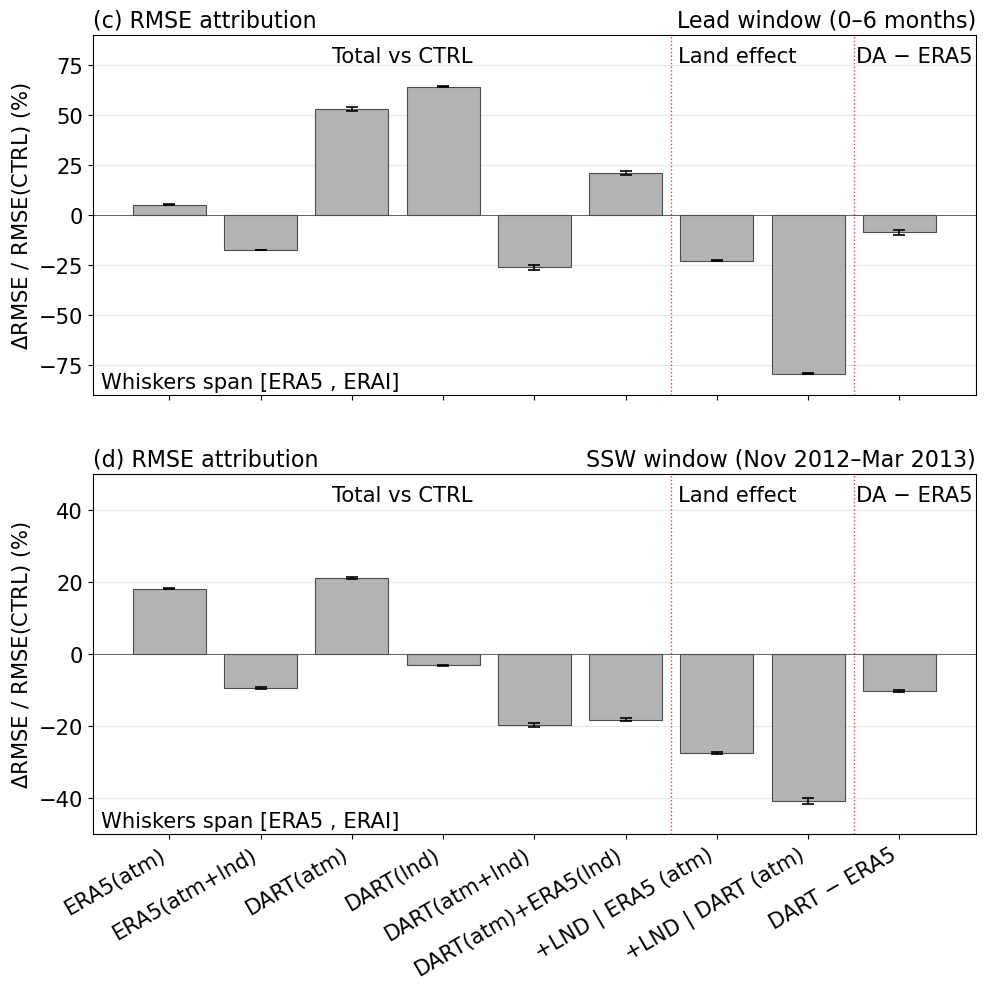

DONE


In [27]:
if __name__ == "__main__":
    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    ssw_dir = Path(work_dir) / "figure_data" / "ssw_monthly"
    out_dir = Path("./ssw_figs").resolve()
    out_dir.mkdir(parents=True, exist_ok=True)

    exp_list = ["DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTAE", "DARTBA", "CTRL"]

    style_map = {
        "CTRL":   dict(color="0.55", linestyle="-",  linewidth=1.0),
        "DARTOP": dict(color="tab:red", linestyle="-",  linewidth=1.0),
        "ERA5OP": dict(color="tab:red", linestyle="--", linewidth=1.0),
        "ERA5DL": dict(color="tab:blue", linestyle="-",  linewidth=1.0),
        "ERA5BL": dict(color="tab:blue", linestyle=":",  linewidth=2.0),
        "DARTBL": dict(color="tab:purple", linestyle="-",  linewidth=1.0),
        "DARTBA": dict(color="tab:purple", linestyle="--", linewidth=1.0),
        "DARTAE": dict(color="tab:purple", linestyle=":",  linewidth=2.0),
    }

    # NOTE: cfg.ref is not used by the *_two_refs methods; set a safe placeholder.
    plot_cfg = SswMonthlyPlotConfig(
        diag_dir=ssw_dir,
        ref="ERA5",  # placeholder
        exp_keys=exp_list,
        style_map=style_map,
        ssw_window=("2012-11", "2013-03"),
        running_rmse_months=3,
    )
    plotter = SswMonthlyPlotter(plot_cfg)

    refs = ("ERA5", "ERAI")

    # 3) Early-lead attribution (months 0–6), U @ 10 hPa
    # IMPORTANT: this should compute RMSE from bias time series (since rmse_lead00_06 not saved).
    plotter.plot_rmse_attribution_bars_two_refs(
        var="u_55_65N",
        plev_hpa=10.0,
        window_types=["lead","ssw"],
        windows=[(0, 6),None],
        ylims=[(-90,90),(-50,50)],
        refs=refs,
        include_dartop_minus_era5op=True,
        out_dir=out_dir,
        show=True,
        figsize=(10,10),
        fontz=16,
        fig_idx=2,
        wspace=0.15,
        hspace=0.22
    )
    
    print("DONE")


Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/ssw_analysis/ssw_figs/ssw_bias_runningRMSE_u_twoRefs.png
Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/ssw_analysis/ssw_figs/ssw_bias_runningRMSE_u_twoRefs.pdf


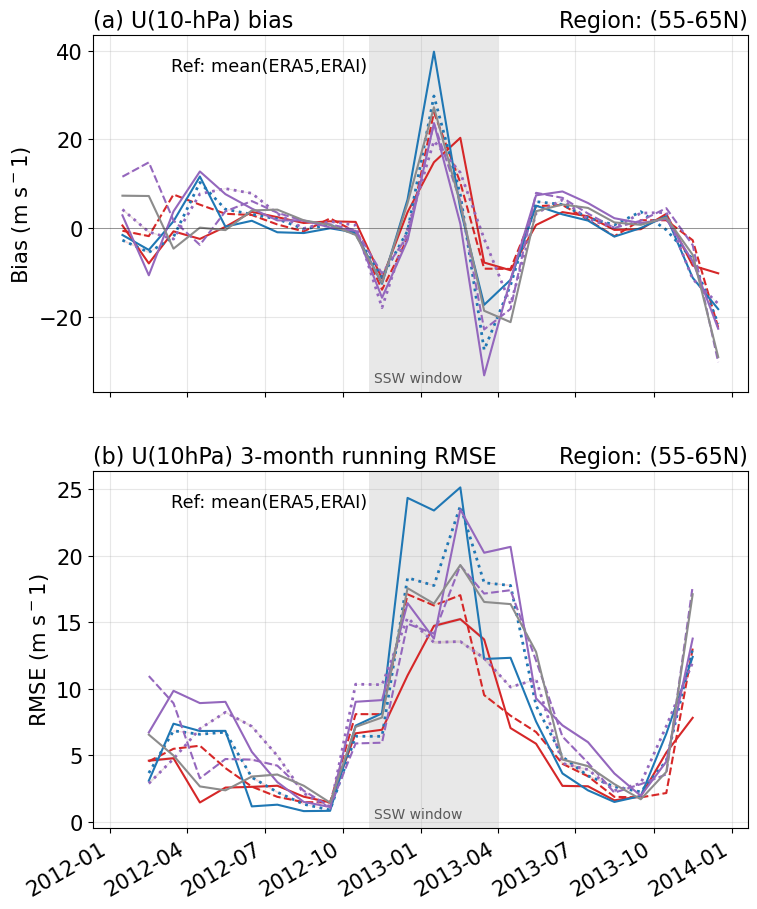

DONE


In [30]:
if __name__ == "__main__":
    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    ssw_dir = Path(work_dir) / "figure_data" / "ssw_monthly"
    out_dir = Path("./ssw_figs").resolve()
    out_dir.mkdir(parents=True, exist_ok=True)

    exp_list = ["DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTAE", "DARTBA", "CTRL"]

    style_map = {
        "CTRL":   dict(color="0.55", linestyle="-",  linewidth=1.5),
        "DARTOP": dict(color="tab:red", linestyle="-",  linewidth=1.5),
        "ERA5OP": dict(color="tab:red", linestyle="--", linewidth=1.5),
        "ERA5DL": dict(color="tab:blue", linestyle="-",  linewidth=1.5),
        "ERA5BL": dict(color="tab:blue", linestyle=":",  linewidth=2.0),
        "DARTBL": dict(color="tab:purple", linestyle="-",  linewidth=1.5),
        "DARTBA": dict(color="tab:purple", linestyle="--", linewidth=1.5),
        "DARTAE": dict(color="tab:purple", linestyle=":",  linewidth=2.0),
    }

    # NOTE: cfg.ref is not used by the *_two_refs methods; set a safe placeholder.
    plot_cfg = SswMonthlyPlotConfig(
        diag_dir=ssw_dir,
        ref="ERA5",  # placeholder
        exp_keys=exp_list,
        style_map=style_map,
        ssw_window=("2012-11", "2013-03"),
        running_rmse_months=3,
    )
    plotter = SswMonthlyPlotter(plot_cfg)

    refs = ("ERA5", "ERAI")

    # 2) Mechanistic: bias + running RMSE for U (center line + band)
    fig_name = f"{out_dir}/ssw_bias_runningRMSE_u_twoRefs.png"

    plotter.plot_bias_and_running_rmse_two_refs(
        var="u_55_65N",
        plevs_hpa=(10.0,), #plevs_hpa=(10.0, 100.0),
        refs=refs,
        center="mean",
        figsize=(8,10),
        fontz=16,
        ncols = 1,
        nrows = 2,
        fig_idx = 0,
        wspace=0.15,
        hspace=0.22,
        out_png=fig_name,
        show=True,
        legend_on = False, 
    )

    print("DONE")


Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/ssw_analysis/ssw_figs/ssw_bias_timeseries_twoRefs.png
Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/ssw_analysis/ssw_figs/ssw_bias_timeseries_twoRefs.pdf


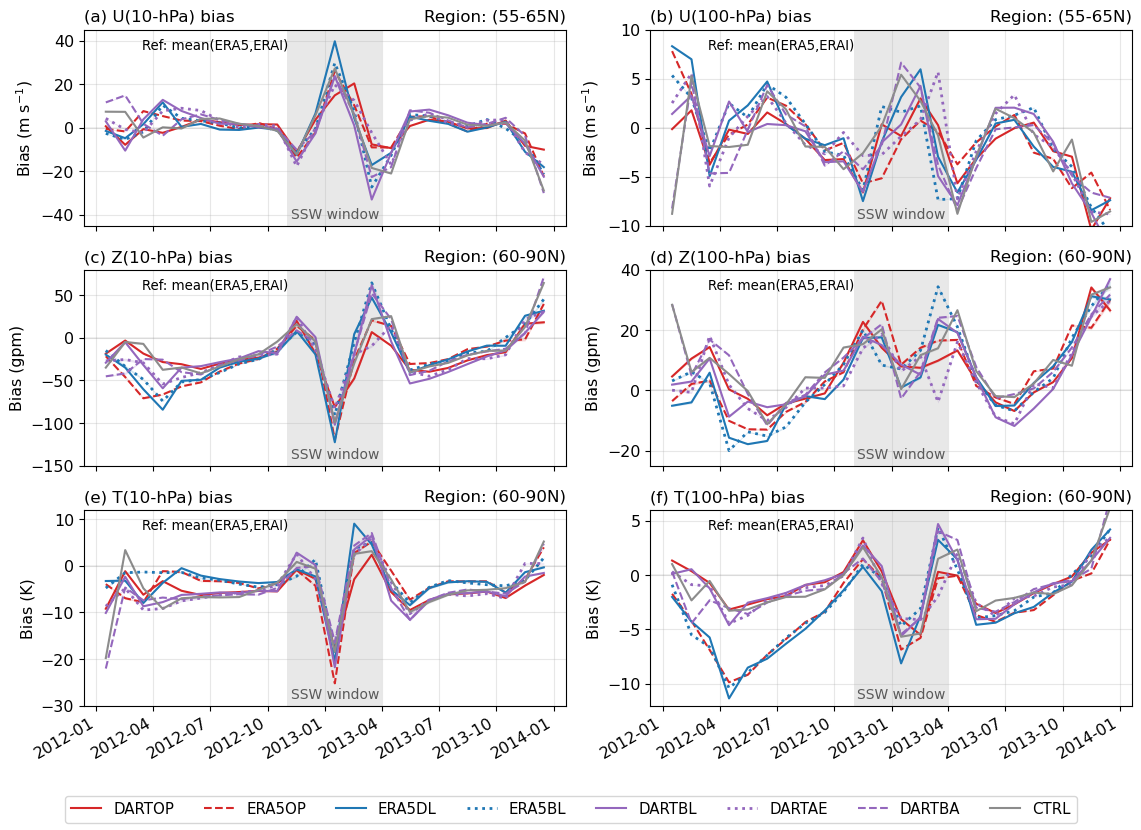

DONE


In [136]:
if __name__ == "__main__":
    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    ssw_dir = Path(work_dir) / "figure_data" / "ssw_monthly"
    out_dir = Path("./ssw_figs").resolve()
    out_dir.mkdir(parents=True, exist_ok=True)

    exp_list = ["DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTAE", "DARTBA", "CTRL"]

    style_map = {
        "CTRL":   dict(color="0.55", linestyle="-",  linewidth=1.5),
        "DARTOP": dict(color="tab:red", linestyle="-",  linewidth=1.5),
        "ERA5OP": dict(color="tab:red", linestyle="--", linewidth=1.5),
        "ERA5DL": dict(color="tab:blue", linestyle="-",  linewidth=1.5),
        "ERA5BL": dict(color="tab:blue", linestyle=":",  linewidth=2.0),
        "DARTBL": dict(color="tab:purple", linestyle="-",  linewidth=1.5),
        "DARTBA": dict(color="tab:purple", linestyle="--", linewidth=1.5),
        "DARTAE": dict(color="tab:purple", linestyle=":",  linewidth=2.0),
    }

    # NOTE: cfg.ref is not used by the *_two_refs methods; set a safe placeholder.
    plot_cfg = SswMonthlyPlotConfig(
        diag_dir=ssw_dir,
        ref="ERA5",  # placeholder
        exp_keys=exp_list,
        style_map=style_map,
        ssw_window=("2012-11", "2013-03"),
        running_rmse_months=3,
    )
    plotter = SswMonthlyPlotter(plot_cfg)

    refs = ("ERA5", "ERAI")

    # 1) Bias time series: U/Z/T at 10 & 100 hPa (center line + band)
    plotter.plot_bias_timeseries_two_refs(
        refs=refs,
        center="mean",   # or "ERA5" / "ERAI"
        out_png=out_dir / "ssw_bias_timeseries_twoRefs.png",
        show=True,
    )

    print("DONE")


Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/ssw_analysis/ssw_figs/ssw_evolution_raw_10hPa.png
Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/ssw_analysis/ssw_figs/ssw_evolution_raw_10hPa.pdf


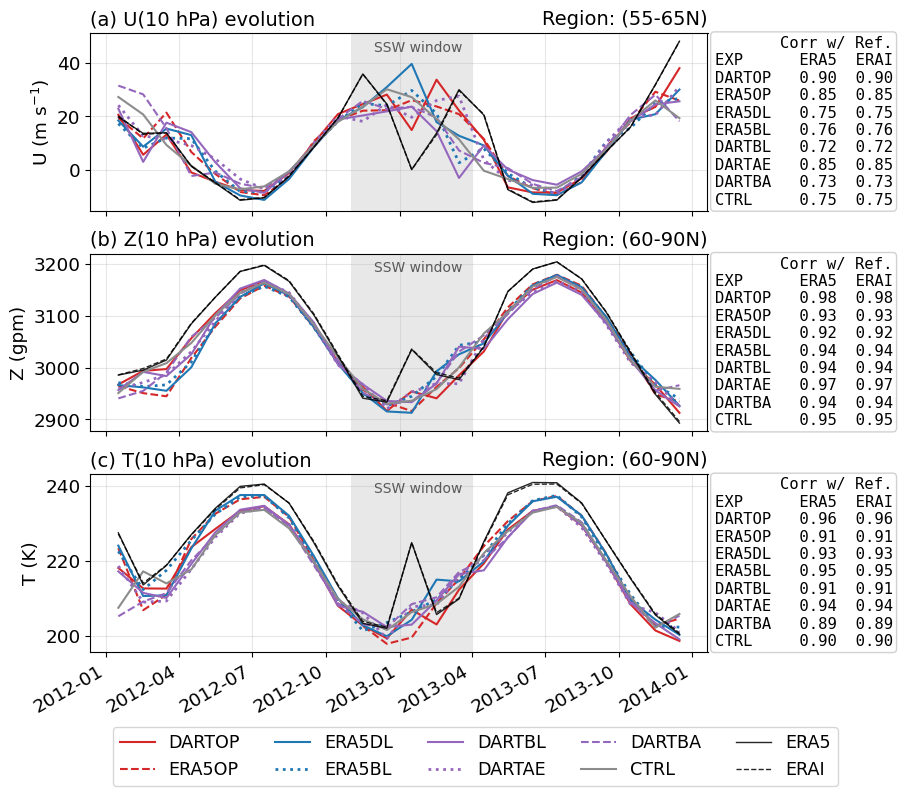

Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/ssw_analysis/ssw_figs/ssw_evolution_raw_100hPa.png
Wrote: /lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/ssw_analysis/ssw_figs/ssw_evolution_raw_100hPa.pdf


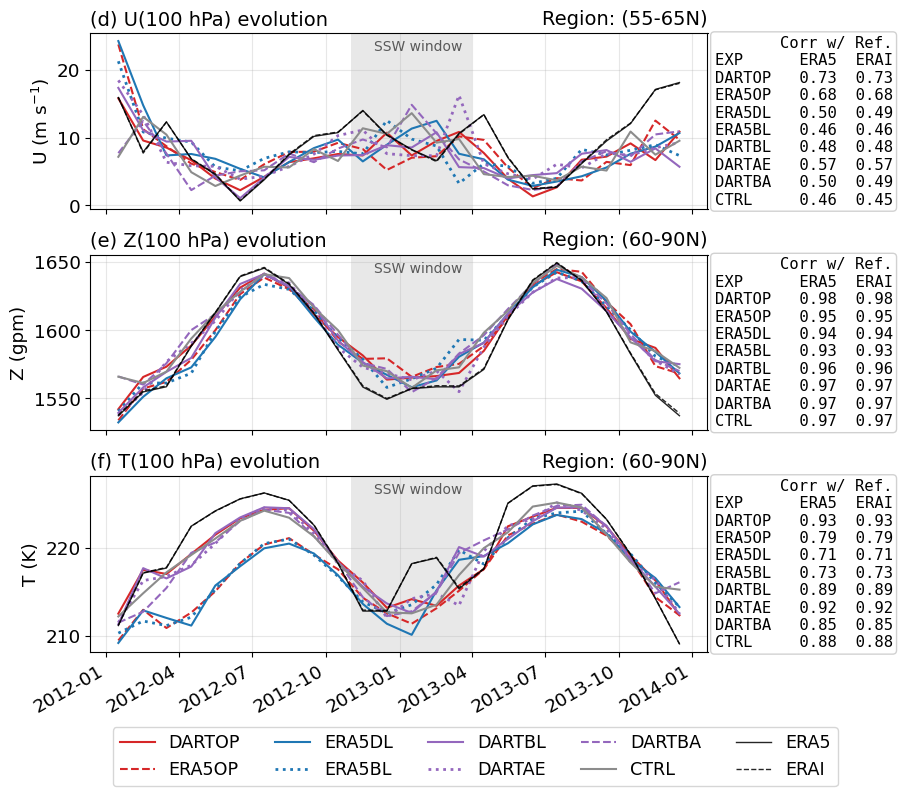

DONE


In [176]:
if __name__ == "__main__":
    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    ssw_dir = Path(work_dir) / "figure_data" / "ssw_monthly"
    out_dir = Path("./ssw_figs").resolve()
    out_dir.mkdir(parents=True, exist_ok=True)

    exp_list = ["DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTAE", "DARTBA", "CTRL"]

    style_map = {
        "ERA5":   dict(color="black", linestyle="-",  linewidth=1.5),
        "ERAI":   dict(color="black", linestyle="--",  linewidth=1.5),
        "CTRL":   dict(color="0.55", linestyle="-",  linewidth=1.5),
        "DARTOP": dict(color="tab:red", linestyle="-",  linewidth=1.5),
        "ERA5OP": dict(color="tab:red", linestyle="--", linewidth=1.5),
        "ERA5DL": dict(color="tab:blue", linestyle="-",  linewidth=1.5),
        "ERA5BL": dict(color="tab:blue", linestyle=":",  linewidth=2.0),
        "DARTBL": dict(color="tab:purple", linestyle="-",  linewidth=1.5),
        "DARTBA": dict(color="tab:purple", linestyle="--", linewidth=1.5),
        "DARTAE": dict(color="tab:purple", linestyle=":",  linewidth=2.0),
    }

    # NOTE: cfg.ref is not used by the *_two_refs methods; set a safe placeholder.
    plot_cfg = SswMonthlyPlotConfig(
        diag_dir=ssw_dir,
        ref="ERA5",  # placeholder
        exp_keys=exp_list,
        style_map=style_map,
        ssw_window=("2012-11", "2013-03"),
        running_rmse_months=3,
    )
    plotter = SswMonthlyPlotter(plot_cfg)

    refs = ("ERA5", "ERAI")
    plotter.plot_ssw_evolution_threepanel_raw(
        out_prefix=out_dir / "ssw_evolution_raw",
        refs=("ERA5", "ERAI"),
        plot_refs=True,
        show=True,
        fontz=14,
        ncols=1,
        nrows=3,
        figsize=(10,8)
    )

    print("DONE")
